## 南瓜品种与颜色

加载所需的库和数据集。将数据转换为包含数据子集的数据框：

让我们来看看颜色与品种之间的关系


In [1]:
import pandas as pd
import numpy as np

full_pumpkins = pd.read_csv('../data/US-pumpkins.csv')

full_pumpkins.head()


,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,...,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
0,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,4/29/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
1,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,5/6/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
2,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
3,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
4,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,11/5/16,90.0,100.0,90.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


### 数据清洗与类别可视化

从原始南瓜数据中提取分类任务需要的信息，并观察南瓜品种与颜色的关系

#### Step 1 提取需要的列

In [2]:
columns_to_select = ['City Name', 'Package', 'Variety', 'Origin', 'Item Size', 'Color']

pumpkins = full_pumpkins.loc[:, columns_to_select]
print("清洗前：", pumpkins.shape)

pumpkins.dropna(inplace=True)
print("清洗后：", pumpkins.shape, "\n")
print(pumpkins.info())

清洗前： (1757, 6)
清洗后： (991, 6) 

<class 'pandas.DataFrame'>
Index: 991 entries, 2 to 1698
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   City Name  991 non-null    str  
 1   Package    991 non-null    str  
 2   Variety    991 non-null    str  
 3   Origin     991 non-null    str  
 4   Item Size  991 non-null    str  
 5   Color      991 non-null    str  
dtypes: str(6)
memory usage: 54.2 KB
None


#### Step 2 观察类别数量

In [3]:
print(pumpkins['Color'].value_counts())
print("\n")
print(pumpkins['Variety'].value_counts())

Color
ORANGE    835
WHITE     156
Name: count, dtype: int64


Variety
HOWDEN TYPE          531
PIE TYPE             191
MINIATURE            130
HOWDEN WHITE TYPE     47
BIG MACK TYPE         43
FAIRYTALE             21
CINDERELLA            14
BLUE TYPE              7
KNUCKLE HEAD           7
Name: count, dtype: int64


#### Step 3 使用 Seaborn 绘制类别统计图

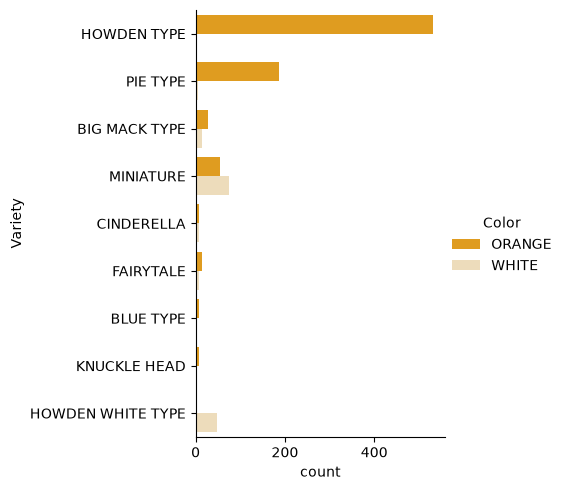

In [4]:
import seaborn as sns

palette = {'ORANGE': 'orange', 'WHITE': 'wheat'}

sns.catplot(data=pumpkins, y='Variety', hue='Color', kind="count", palette=palette)

### 实验 2：特征编码与标签编码

数据包含大量字符串，但机器学习模型通常需要数值形式的输入，因此需要将类别转换成数字，这就是编码

#### 特征编码

In [5]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. 对有序特征编码
item_size_categories = [['sml', 'med', 'med-lge', 'lge', 'xlge', 'jbo', 'exjbo']]
oridinal_feature = ['Item Size']
oridinal_encoder = OrdinalEncoder(categories=item_size_categories)

# 2. 对无序类别特征编码
categorical_features = ['City Name', 'Package', 'Variety', 'Origin']
categorical_encoder = OneHotEncoder(sparse_output=False)

# 3. 合并两种编码方式
ct = ColumnTransformer(transformers=[
    ('ord', oridinal_encoder, oridinal_feature),
    ('cat', categorical_encoder, categorical_features)
])

ct.set_output(transform='pandas')
encoded_features = ct.fit_transform(pumpkins)
encoded_features.head()

,ord__Item Size,cat__City Name_ATLANTA,cat__City Name_BALTIMORE,cat__City Name_BOSTON,cat__City Name_CHICAGO,cat__City Name_COLUMBIA,cat__City Name_DALLAS,cat__City Name_DETROIT,cat__City Name_LOS ANGELES,cat__City Name_MIAMI,...,cat__Origin_MICHIGAN,cat__Origin_NEW JERSEY,cat__Origin_NEW YORK,cat__Origin_NORTH CAROLINA,cat__Origin_OHIO,cat__Origin_PENNSYLVANIA,cat__Origin_TENNESSEE,cat__Origin_TEXAS,cat__Origin_VERMONT,cat__Origin_VIRGINIA
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,3.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,3.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### 标签编码

In [6]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
encoded_label = label_encoder.fit_transform(pumpkins['Color'])

print(label_encoder.classes_)
print(encoded_label[:10])

['ORANGE' 'WHITE']
[0 0 0 0 0 0 0 0 0 0]


#### 编码后的特征和标签合并

In [ ]:
encoded_pumpkins = encoded_features.assign(Color=encoded_label)
encoded_pumpkins.head()

print("原始数据形状：", pumpkins.shape)
print("编码后数据形状：", encoded_pumpkins.shape)

print("\n标签分布：")
print(encoded_pumpkins['Color'].value_counts())


原始数据形状： (991, 6)
编码后数据形状： (991, 49)

标签分布：
Color
0    835
1    156
Name: count, dtype: int64


### 实验 3：分析 Item Size、Variety 和 Color

两种可视化方法，帮助我们判断南瓜大小、品种和颜色之间是否存在关系

#### Step 1 使用分类箱线图

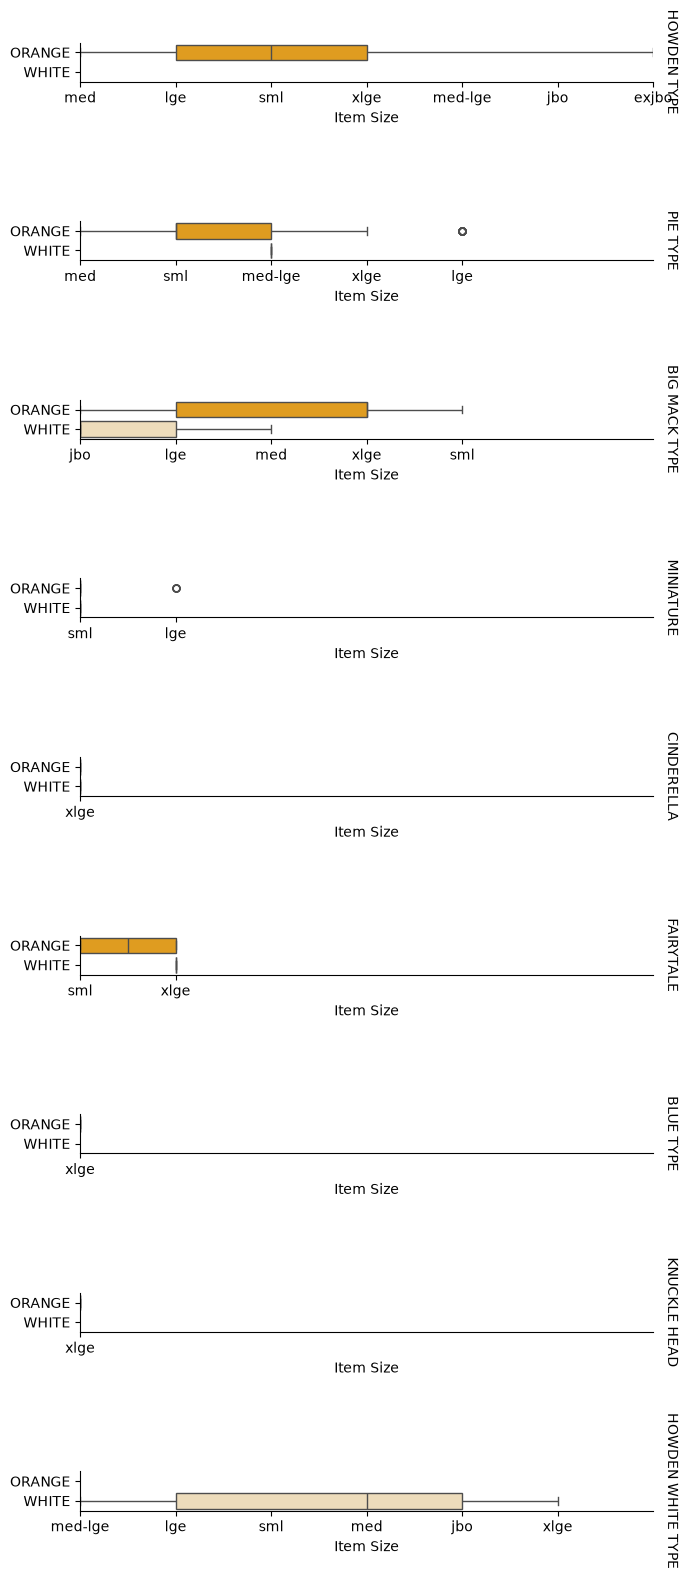

In [8]:
import seaborn as sns

palette = {'ORANGE': 'orange', 'WHITE': 'wheat'}

# 保留原始数据，单独创建可视化数据
plot_pumpkins = pumpkins.copy()
plot_pumpkins['Item Size'] = encoded_pumpkins['ord__Item Size']

g = sns.catplot(
        data=pumpkins,
        x="Item Size", y="Color", row='Variety', hue="Color",
        kind="box", orient="h",
        sharex=False, margin_titles=True,
        height=1.8, aspect=4, palette=palette, dodge=False, legend=False
    )

g.set(xlabel="Item Size", ylabel="").set(xlim=(0, 6))
g.set_titles(row_template="{row_name}")

#### Step 2 使用 Swarm Plot（蜂群图）

c:\Users\24303\miniconda3\envs\ai-learning-os\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 35.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\24303\miniconda3\envs\ai-learning-os\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 63.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\24303\miniconda3\envs\ai-learning-os\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 21.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


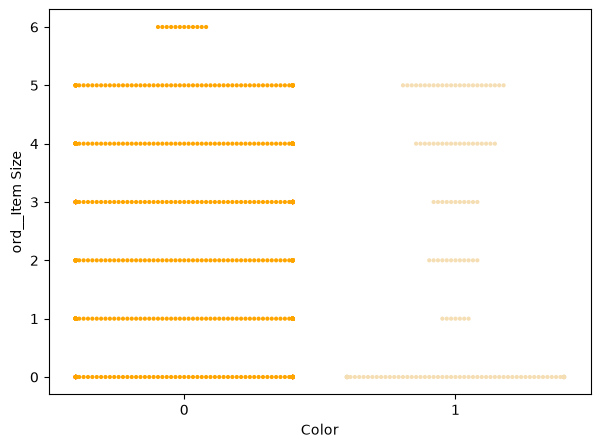

In [9]:
import matplotlib.pyplot as plt

palette = {0: 'orange', 1: 'wheat'}

plt.figure(figsize=(7, 5))

sns.swarmplot(data=encoded_pumpkins, x='Color', y='ord__Item Size', hue='Color',
              palette=palette, legend=False, size=3)

plt.show()

### 实验 4：建立 Logistic Regression 模型

#### 划分训练集与测试集

In [19]:
from sklearn.model_selection import train_test_split

X = encoded_pumpkins.drop(columns=['Color'])
y = encoded_pumpkins['Color']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("训练集形状：", X_train.shape)
print("测试集形状：", X_test.shape)


训练集形状： (792, 48)
测试集形状： (199, 48)


#### 训练逻辑回归模型

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       166
           1       0.85      0.67      0.75        33

    accuracy                           0.92       199
   macro avg       0.89      0.82      0.85       199
weighted avg       0.92      0.92      0.92       199



### 实验 5：混淆矩阵与 ROC/AUC

#### Step 1：实际生成混淆矩阵

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions)

print(cm)

[[162   4]
 [ 11  22]]


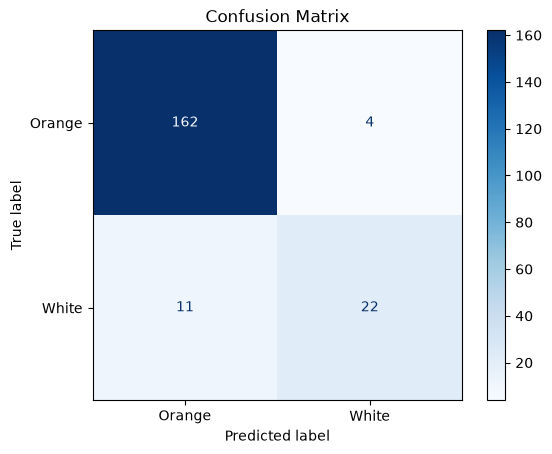

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, predictions, 
                                        display_labels=['Orange', 'White'], cmap='Blues')

plt.title("Confusion Matrix")
plt.show()

#### Step 2：ROC 曲线

In [23]:
y_scores = model.predict_proba(X_test)

print(y_scores[:5])
print(model.classes_)


[[0.63000373 0.36999627]
 [0.51907011 0.48092989]
 [0.93319188 0.06680812]
 [0.99044033 0.00955967]
 [0.99525916 0.00474084]]
[0 1]


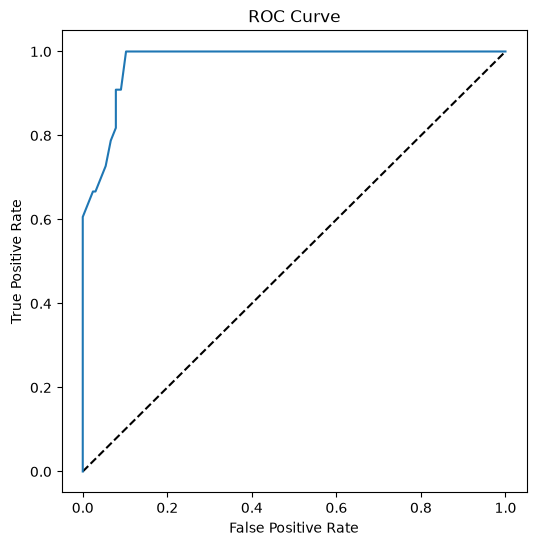

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 获取白色类别的预测概率
y_scores = model.predict_proba(X_test)[:, 1]

# 计算不同阈值下的 FPR、TPR
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

plt.figure(figsize=(6, 6))

# 随机分类基线
plt.plot([0, 1], [0, 1], 'k--')

# ROC 曲线
plt.plot(fpr, tpr)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

#### Step 3 计算 AUC

In [25]:
auc = roc_auc_score(y_test, y_scores)

print("AUC:", auc)

AUC: 0.9749908725812341


## Challenge：独立完成一次二分类

先使用 Scikit-learn 自带的 Iris（鸢尾花）数据集

In [10]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

X = iris.data
y = (iris.target == 0).astype(int)

print(X.head())
print(y.value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
target
0    100
1     50
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

iris_model = LogisticRegression(max_iter=1000)
iris_model.fit(X_train, y_train)

pred = iris_model.predict(X_test)

print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



[[19  0]
 [ 0 11]]


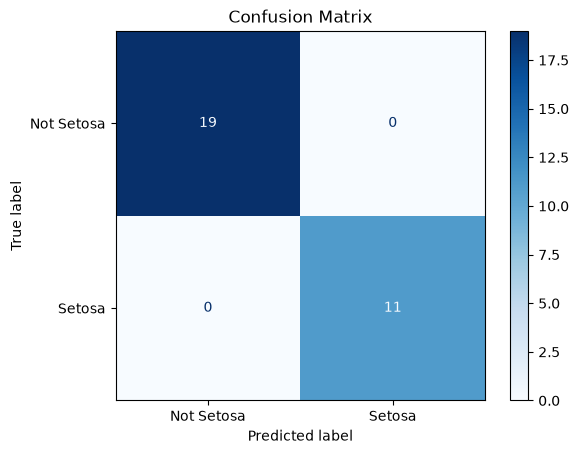

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Not Setosa', 'Setosa'], cmap='Blues')

plt.title("Confusion Matrix")
plt.show()

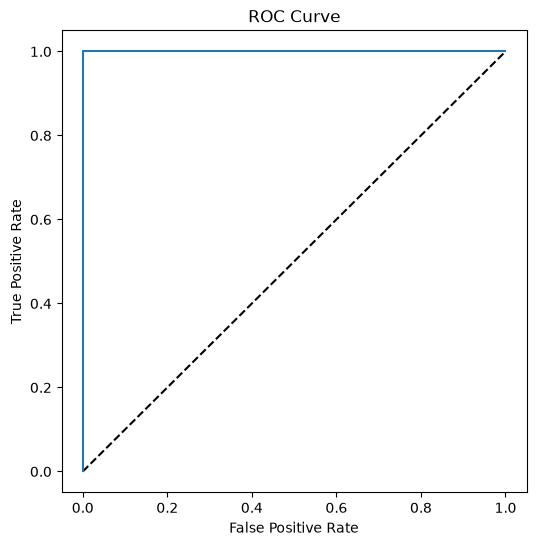

AUC: 1.0


In [18]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_scores = iris_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_scores)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

auc = roc_auc_score(y_test, y_scores)
print("AUC:", auc)

In [19]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    X, y,
    cv=cv,
    scoring='accuracy'
)

print("每折 Accuracy:", scores)
print("平均 Accuracy:", scores.mean())
print("标准差:", scores.std())

每折 Accuracy: [1. 1. 1. 1. 1.]
平均 Accuracy: 1.0
标准差: 0.0


## Assignment：重新训练南瓜分类模型

使用更完整的原始南瓜数据，重新建立逻辑回归模型

### Step 1：检查原始数据

In [20]:
data = full_pumpkins.copy()

data = data[data['Color'].isin(['ORANGE', 'WHITE'])].copy()

print("数据形状：", data.shape)
print("\n各类别数量：")
print(data['Color'].value_counts())

print("\n各列缺失数量：")
print(data.isnull().sum())

数据形状： (1129, 26)

各类别数量：
Color
ORANGE    916
WHITE     213
Name: count, dtype: int64

各列缺失数量：
City Name             0
Type               1128
Package               0
Variety               0
Sub Variety         909
Grade              1129
Date                  0
Low Price             0
High Price            0
Mostly Low           89
Mostly High          89
Origin                0
Origin District    1023
Item Size           138
Color                 0
Environment        1129
Unit of Sale       1005
Quality            1129
Condition          1129
Appearance         1129
Storage            1129
Crop               1129
Repack                0
Trans Mode         1129
Unnamed: 24        1129
Unnamed: 25        1040
dtype: int64


### Step 2：初步选择特征

In [26]:
data['Month'] = pd.to_datetime(data['Date'], format='%m/%d/%y', errors='coerce').dt.month

selected_features = ['City Name', 'Package', 'Variety', 'Origin', 'Item Size', 'Month']

X = data[selected_features].copy()
y = data['Color'].copy()

print("特征形状：", X.shape)
print("\n各特征缺失率：")
print((X.isnull().mean() * 100).round(2))

print("\n特征数据类型：")
print(X.dtypes)

特征形状： (1129, 6)

各特征缺失率：
City Name     0.00
Package       0.00
Variety       0.00
Origin        0.00
Item Size    12.22
Month         0.00
dtype: float64

特征数据类型：
City Name      str
Package        str
Variety        str
Origin         str
Item Size      str
Month        int32
dtype: object


### Step 3：特征编码

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=0, stratify=y)

print("训练集形状：", X_train.shape)
print("测试集形状：", X_test.shape)

print("\n训练集类别比例：")
print(y_train.value_counts(normalize=True))

print("\n测试集类别比例：")
print(y_test.value_counts(normalize=True))

训练集形状： (903, 6)
测试集形状： (226, 6)

训练集类别比例：
Color
ORANGE    0.811739
WHITE     0.188261
Name: proportion, dtype: float64

测试集类别比例：
Color
ORANGE    0.809735
WHITE     0.190265
Name: proportion, dtype: float64


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_features = ['City Name', 'Package', 'Variety', 'Origin', 'Item Size']

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

numeric_features = ['Month']

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('cat', categorical_pipeline, categorical_features),
    ('num', numeric_pipeline, numeric_features)
])

In [30]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print("训练集处理后：", X_train_preprocessed.shape)
print("测试集处理后：", X_test_preprocessed.shape)

print("编码后特征数量：",
      len(preprocessor.get_feature_names_out()))

训练集处理后： (903, 61)
测试集处理后： (226, 61)
编码后特征数量： 61


### Step 4：模型

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=0))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("前10个预测结果：")
print(predictions[:10])

print("\n前10个真实标签：")
print(y_test.iloc[:10].values)

前10个预测结果：
['WHITE' 'ORANGE' 'WHITE' 'ORANGE' 'ORANGE' 'WHITE' 'ORANGE' 'WHITE'
 'ORANGE' 'ORANGE']

前10个真实标签：
<StringArray>
[ 'WHITE', 'ORANGE',  'WHITE', 'ORANGE', 'ORANGE',  'WHITE', 'ORANGE',
 'ORANGE', 'ORANGE', 'ORANGE']
Length: 10, dtype: str


In [34]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:")
print(classification_report(y_test, predictions))

Accuracy: 0.915929203539823

Classification Report:
              precision    recall  f1-score   support

      ORANGE       0.93      0.97      0.95       183
       WHITE       0.85      0.67      0.75        43

    accuracy                           0.92       226
   macro avg       0.89      0.82      0.85       226
weighted avg       0.91      0.92      0.91       226



[[178   5]
 [ 14  29]]


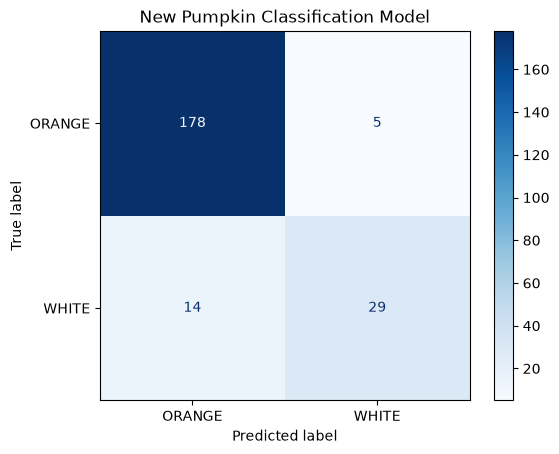

In [35]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions, labels=['ORANGE', 'WHITE'])

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=['ORANGE', 'WHITE']
).plot(cmap='Blues')

plt.title("New Pumpkin Classification Model")
plt.show()


In [36]:
from sklearn.metrics import roc_auc_score

# 找到 WHITE 对应的概率列
classes = model.named_steps['classifier'].classes_

white_index = list(classes).index('WHITE')

white_probabilities = model.predict_proba(X_test)[
    :, white_index
]

auc = roc_auc_score(
    y_test == 'WHITE',
    white_probabilities
)

print("AUC:", auc)

AUC: 0.9738848646587877
